# 070 CASE 130 — Coregistration: aligning dates to a fraction of a pixel

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** How well do two Sentinel-2 dates line up, and which method measures the remaining shift?

**Area:** Farmland around Eslöv (Skåne): 8 October 2023 and 29 July 2024.

**Partners:** RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Contains modified Copernicus Sentinel data 2023 and 2024.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus Jupyter and the plotting
libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1abd4653cb843a75557b05c09915fb85904" jupyterlab folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own DES
account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password; see [digitalearth.se](https://digitalearth.se) for access. Every data fetch goes through
that login, nothing is saved in the notebook, and without a login the fetch stops with an error.
With EGI, the openEO client keeps a refresh token in your home directory so later runs log in
without the browser; on a shared computer account, use the password login instead.
There is no synthetic fallback: every figure comes from real Sentinel-2 data. A run takes about two minutes.

## Log in to Digital Earth Sweden

In [ ]:
from getpass import getpass

import imint.fetch
import openeo
from IPython.display import clear_output

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
try:
    if LOGIN_METHOD == "password":
        user, password = input("DES username: "), getpass("DES password: ")
        if not (user and password):
            raise ValueError("enter both a DES username and a password")
        des.authenticate_basic(user, password)
    else:
        des.authenticate_oidc(provider_id="egi")
finally:
    user = password = None  # never keep the password, even when the login fails
    clear_output()  # keep the typed username and the login link out of a saved notebook


def des_connection(token=None, token_path=None):
    """Every IMINT Engine fetch below uses this login and no other credentials on the machine."""
    return des


assert callable(getattr(imint.fetch, "_connect", None)), "this engine version has no _connect"
imint.fetch._connect = des_connection  # the pinned engine has no public parameter for a connection yet
print("Logged in to Digital Earth Sweden.")


## 1. Method

```
two dates → fetch_des_data (snapped to the national 10 m grid) → estimate the residual shift → align
```

Time series analysis assumes that a pixel is the same piece of ground on every date. Snapping each
scene to the national 10 m grid removes whole-pixel offsets; what remains is a fraction of a pixel.
Two estimators measure it: phase correlation compares the images' frequency content, and mutual
information finds the shift that makes the two images most predictable from each other. Between an
autumn and a summer image the fields look different, which can mislead phase correlation.

## 2. Area and data

The map is interactive when the notebook runs in Jupyter; GitHub's viewer shows only a placeholder for it.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    assert imint.fetch._connect is des_connection, "run the Log in cell first"
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud)
    nodata = np.all(np.stack([a == 0 for a in scene.bands.values()]), axis=0)
    if nodata.mean() > 0.01:  # the archive sometimes holds only part of a scene
        raise ValueError(f"{date}: {nodata.mean():.0%} of the area has no data in this DES scene; use another date")
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud and shadow {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene


def true_colour(scene, top=0.25):
    """True colour with a fixed stretch, so different dates are comparable."""
    return np.clip(np.dstack([scene.bands[b] for b in ("B04", "B03", "B02")]) / top, 0, 1)

AOI = {"west": 13.20, "south": 55.80, "east": 13.40, "north": 55.90}  # around Eslöv, Skåne
AUTUMN, SUMMER = "2023-10-08", "2024-07-29"

autumn = load_scene(AUTUMN, AOI)
summer = load_scene(SUMMER, AOI)

    Cloud fraction: 0.0%


2023-10-08: 11 bands, 1145 x 1280 px at 10 m, cloud and shadow 0.0% (SCL), CRS EPSG:3006


    Cloud fraction: 0.1%


2024-07-29: 11 bands, 1145 x 1280 px at 10 m, cloud and shadow 0.1% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=11, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#5f3dc4", weight=2, fill=False, popup="Eslöv",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Measure the residual shift

In [4]:
from imint.coregistration import estimate_mi_offset, estimate_subpixel_offset, subpixel_shift

reference, moving = summer.bands["B08"], autumn.bands["B08"]  # near infrared: field and forest edges
mi = np.array(estimate_mi_offset(moving, reference))
pc = np.array(estimate_subpixel_offset(moving, reference))
print(f"residual shift autumn → summer (dy, dx in pixels): mutual information {mi.round(3)}, "
      f"phase correlation {pc.round(3)}")

# Test with a known shift: move the autumn image by (0.4, -0.3) px and see which method finds it
known = np.array([0.4, -0.3])
shifted = subpixel_shift(moving, *known)
for name, estimate, base in [("mutual information", estimate_mi_offset, mi),
                             ("phase correlation", estimate_subpixel_offset, pc)]:
    found = -(np.array(estimate(shifted, reference)) - base)  # estimators return the correcting shift
    print(f"{name:18s} finds the known shift as {found.round(3)}, error {np.abs(found - known).max():.3f} px")

aligned = subpixel_shift(moving, *mi)

residual shift autumn → summer (dy, dx in pixels): mutual information [-0.42   0.014], phase correlation [-0.336 -0.118]


mutual information finds the known shift as [ 0.504 -0.249], error 0.104 px
phase correlation  finds the known shift as [-1.519 -0.3  ], error 1.919 px


## 4. Results

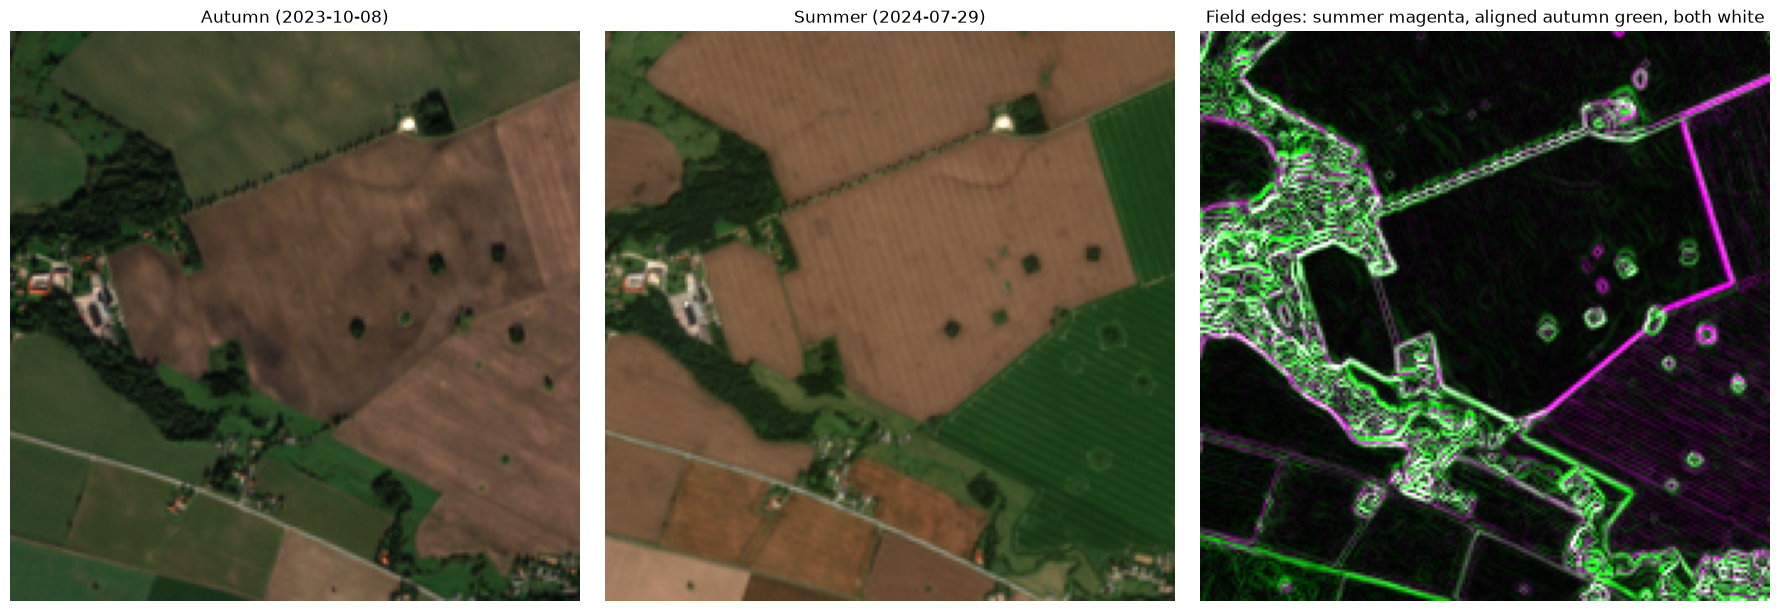

In [5]:
crop = (slice(300, 500), slice(300, 500))  # a 2 x 2 km detail
edges = lambda a: np.hypot(*np.gradient(a))
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(true_colour(autumn)[crop]); axes[0].set_title(f"Autumn ({AUTUMN})")
axes[1].imshow(true_colour(summer)[crop]); axes[1].set_title(f"Summer ({SUMMER})")
overlay = np.dstack([edges(reference)[crop], edges(aligned)[crop], edges(reference)[crop]])
axes[2].imshow(np.clip(overlay / np.nanpercentile(overlay, 99), 0, 1))
axes[2].set_title("Field edges: summer magenta, aligned autumn green, both white")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

After the grid snap the two dates still differ by a fraction of a pixel; the printed residual
says how much. In the known-shift test mutual information found the 0.4 px shift to within about
0.1 px, while phase correlation missed it by almost 2 px: between an autumn and a summer image it
follows the changed fields rather than the geometry. IMINT Engine's
training data uses mutual information for this step.

**Links:** [`imint/coregistration.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/coregistration.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).